In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from scipy import stats
from scipy.signal import welch

## Punto 2

In [23]:


# Rutas RELATIVAS a la raíz del repositorio (iguales para todo el equipo).
# Busca la carpeta "data" subiendo desde donde se abra el notebook.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
DATA_DIR = ROOT / "data"
DIAGNOSTICS_PATH = DATA_DIR / "Diagnostics.xlsx"
SIGNALS_DIR = DATA_DIR / "ECGDataDenoised"

FS = 500                       # Hz
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
DERIVACION = "II"

diagnostics = pd.read_excel(DIAGNOSTICS_PATH)
diagnosis_column = diagnostics.columns[1]          # "Rhythm"

# Normalizar texto de las columnas categóricas (misma lógica que en la Parte 1)
diagnostics[diagnosis_column] = diagnostics[diagnosis_column].astype(str).str.strip().str.upper()
diagnostics["Gender"] = diagnostics["Gender"].astype(str).str.strip().str.upper()

print("Registros:", len(diagnostics))
print("Columnas:", list(diagnostics.columns))

Registros: 10646
Columnas: ['FileName', 'Rhythm', 'Beat', 'PatientAge', 'Gender', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset']


In [6]:
# ARRITMIA SB

sb_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SB")
].copy()
#Esta parte filtra diagnostics y conserva únicamente las filas cuyo diagnóstico sea "SB"


FILENAME_SB = sb_diagnostics["FileName"].astype(str).tolist()
#De los registros que quedaron después del filtro, toma únicamente la columna FileName.
# .tolist() convierte esa columna en una lista de Python,
# por lo tanto, FILENAME_SB contiene los nombres de los archivos correspondientes a los registros diagnosticados como SB.


print(f"\nNúmero de pacientes/registros con SB: {len(FILENAME_SB)}")

#ARRITMIA SR

SR_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SR")
].copy()

FILENAME_SR = SR_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SR: {len(FILENAME_SR)}")

#ARRITMIA AFIB

AFIB_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AFIB")
].copy()

FILENAME_AFIB = AFIB_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AFIB: {len(FILENAME_AFIB)}")

#ARRITMIA ST

ST_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("ST")
].copy()

FILENAME_ST = ST_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con ST: {len(FILENAME_ST)}")

#ARRITMIA AF

AF_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AF")
].copy()

FILENAME_AF = AF_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AF: {len(FILENAME_AF)}")

#ARRITMIA SI

SA_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SA")
].copy()
FILENAME_SA = SA_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SA: {len(FILENAME_SA)}")

#ARRITMIA SVT

SVT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SVT")
].copy()

FILENAME_SVT = SVT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SVT: {len(FILENAME_SVT)}")

#ARRITMIA AT

AT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AT")
].copy()

FILENAME_AT = AT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AT: {len(FILENAME_AT)}")

#ARRITMIA AVNRT

AVNRT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AVNRT")
].copy()

FILENAME_AVNRT = AVNRT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AVNRT: {len(FILENAME_AVNRT)}")

#ARRITMIA AVRT

AVRT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AVRT")
].copy()

FILENAME_AVRT = AVRT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AVRT: {len(FILENAME_AVRT)}")

#ARRITMIA SAAWR

SAAWR_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SAAWR")
].copy()

FILENAME_SAAWR = SAAWR_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SAAWR: {len(FILENAME_SAAWR)}")


Número de pacientes/registros con SB: 3889

Número de pacientes/registros con SR: 1826

Número de pacientes/registros con AFIB: 1780

Número de pacientes/registros con ST: 1568

Número de pacientes/registros con AF: 445

Número de pacientes/registros con SA: 399

Número de pacientes/registros con SVT: 587

Número de pacientes/registros con AT: 121

Número de pacientes/registros con AVNRT: 16

Número de pacientes/registros con AVRT: 8

Número de pacientes/registros con SAAWR: 7


Característica,Valor
Total de registros,10.646
Total de sujetos,10.646
Número de canales,12
Derivaciones,"I, II, III, aVR, aVL, aVF, V1–V6"
Frecuencia de muestreo,500 Hz
Duración de cada registro,10 s


Clase / Arritmia,Registros,Sujetos,Porcentaje
SB,3889,3889,36.53 %
SR,1826,1826,17.15 %
AFIB,1780,1780,16.72 %
ST,1568,1568,14.73 %
AF,445,445,4.18 %
SA,399,399,3.75 %
SVT,587,587,5.51 %
AT,121,121,1.14 %
AVNRT,16,16,0.15 %
AVRT,8,8,0.08 %


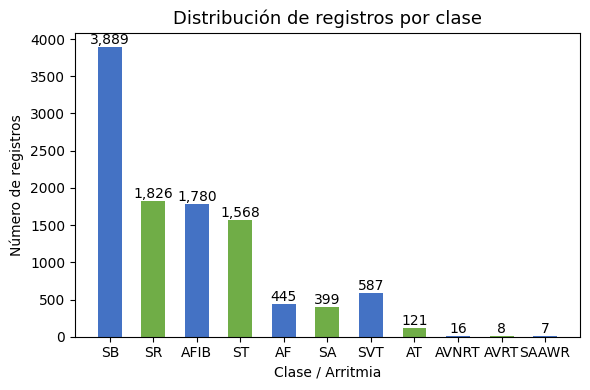

In [9]:

# TABLA CON CARACTERÍSTICAS GENERALES DEL DATASET

# Se crea un DataFrame que contiene las principales características generales del conjunto de datos.
# La primera columna contiene el nombre de cada característica y la segunda columna contiene su valor correspondiente.

tabla_general = pd.DataFrame({
    "Característica": [
        "Total de registros",
        "Total de sujetos",
        "Número de canales",
        "Derivaciones",
        "Frecuencia de muestreo",
        "Duración de cada registro"
    ],
    
    "Valor": [
        "10.646",
        "10.646",
        "12",
        "I, II, III, aVR, aVL, aVF, V1–V6",
        "500 Hz",
        "10 s"
    ]
})

display(
    tabla_general.style
    .hide(axis="index")
    .set_caption("Características generales del conjunto de datos")
    .set_properties(**{
        "text-align": "left",
        "padding": "5px"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("margin-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#4472C4"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("border", "1px solid #D9E2F3")
            ]
        }
    ])
)

# TABLA CON LA DISTRIBUCIÓN DE LAS CLASES

# Se crea un DataFrame con las diferentes clases o ritmospresentes en los registros analizados.
# "Registros" indica cuántos registros pertenecen a cada clase.
# "Sujetos" indica cuántos sujetos pertenecen a cada clase.

tabla_clases = pd.DataFrame({
    "Clase / Arritmia": ["SB", "SR", "AFIB", "ST", "AF", "SA", "SVT", "AT", "AVNRT", "AVRT", "SAAWR"],
    "Registros": [3889, 1826, 1780, 1568, 445, 399, 587, 121, 16, 8, 7],
    "Sujetos": [3889, 1826, 1780, 1568, 445, 399, 587, 121, 16, 8, 7]
})

# Se calcula el porcentaje que representa cada clase respecto al total de 10.646 registros.
# El resultado se multiplica por 100 para expresarlo como porcentaje y se redondea a dos cifras decimales.

tabla_clases["Porcentaje"] = (
    tabla_clases["Registros"] / 10646 * 100
).round(2)

# Se muestra la tabla de distribución aplicando formato.

display(
    tabla_clases.style
    .hide(axis="index")
    .set_caption("Distribución de las clases analizadas")
    .format({"Porcentaje": "{:.2f} %"})
    .set_properties(**{
        "text-align": "center",
        "padding": "5px"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("margin-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#70AD47"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("border", "1px solid #E2F0D9")
            ]
        }
    ])
)



# GRÁFICO DE DISTRIBUCIÓN DE LAS CLASES
# Se crea una figura para mostrar gráficamente la cantidad de registros de cada clase.

plt.figure(figsize=(6, 4))


# Se crea un gráfico de barras.
# En el eje X se colocan las diferentes clases.
# En el eje Y se coloca el número de registros.

barras = plt.bar(
    tabla_clases["Clase / Arritmia"],
    tabla_clases["Registros"],
    color=["#4472C4", "#70AD47"],
    width=0.55
)

plt.title("Distribución de registros por clase", fontsize=13)
plt.xlabel("Clase / Arritmia")
plt.ylabel("Número de registros")



# MOSTRAR EL NÚMERO DE REGISTROS SOBRE CADA BARRA

# Se recorre cada barra del gráfico para obtener su altura, que corresponde al número de registros de esa clase.
for barra in barras:

    # Obtiene la altura de la barra.
    altura = barra.get_height()


    # Coloca el número de registros encima de cada barra.
    # barra.get_x() obtiene la posición horizontal de la barra.
    # barra.get_width() obtiene su ancho.
    # int(altura) convierte el valor a entero.
    # :, permite mostrar los números con separador de miles.

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f"{int(altura):,}",
        ha="center",
        va="bottom"
    )


# Ajusta automáticamente los espacios del gráfico para evitar que los elementos queden cortados.
plt.tight_layout()

# Muestra el gráfico.
plt.show()


In [11]:


# Se agrupan en un diccionario los DataFrames que ya se filtraron arriba para cada ritmo
ritmos = {
    "SB": sb_diagnostics, "SR": SR_diagnostics, "AFIB": AFIB_diagnostics, "ST": ST_diagnostics,
    "AF": AF_diagnostics, "SA": SA_diagnostics, "SVT": SVT_diagnostics, "AT": AT_diagnostics,
    "AVNRT": AVNRT_diagnostics, "AVRT": AVRT_diagnostics, "SAAWR": SAAWR_diagnostics,
}
orden = list(ritmos.keys())

COLOR_M = "#4472C4"   # hombres
COLOR_F = "#E57373"   # mujeres

,Hombres,Mujeres,% Hombres,% Mujeres
Ritmo,,,,
SB,2481,1408,63.8,36.2
SR,802,1024,43.9,56.1
AFIB,1041,739,58.5,41.5
ST,799,769,51.0,49.0
AF,257,188,57.8,42.2
SA,223,176,55.9,44.1
SVT,279,308,47.5,52.5
AT,64,57,52.9,47.1
AVNRT,4,12,25.0,75.0


Chi² = 254.0, gl = 10, p = 7.69e-49


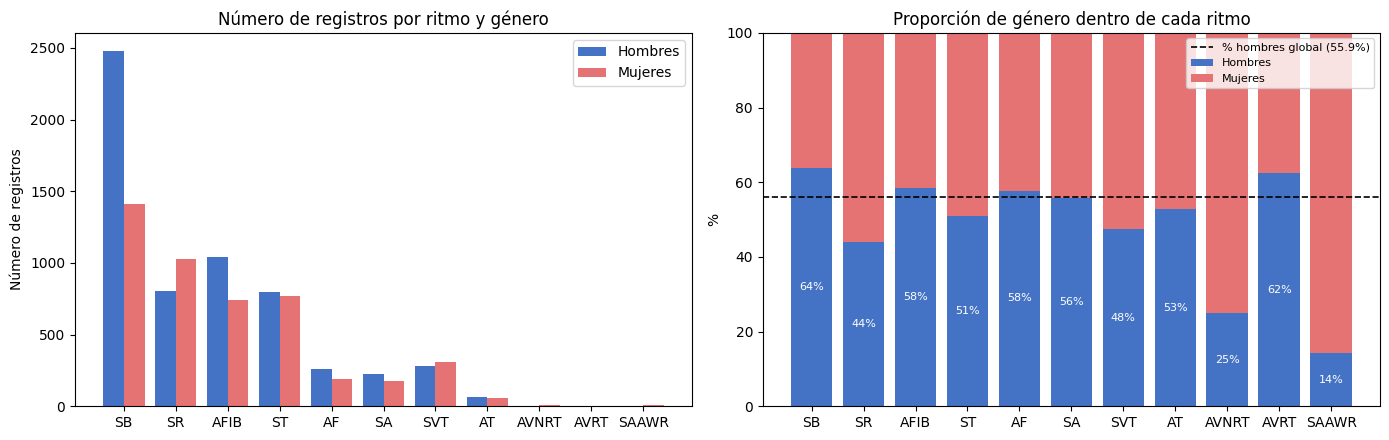

In [12]:
# TABLA: número y porcentaje de hombres y mujeres dentro de cada ritmo
filas = []
for sigla, df in ritmos.items():
    n_m = (df["Gender"] == "MALE").sum()
    n_f = (df["Gender"] == "FEMALE").sum()
    filas.append({"Ritmo": sigla, "Hombres": n_m, "Mujeres": n_f,
                  "% Hombres": n_m / len(df) * 100, "% Mujeres": n_f / len(df) * 100})
tabla_genero = pd.DataFrame(filas).set_index("Ritmo")
display(tabla_genero.round(1))

# Proporción global de hombres en toda la base (línea de referencia)
p_hombres_global = (diagnostics["Gender"] == "MALE").mean() * 100

# Prueba chi-cuadrado: ¿el ritmo depende del género?
chi2, p_chi, gl, _ = stats.chi2_contingency(tabla_genero[["Hombres", "Mujeres"]])
print(f"Chi² = {chi2:.1f}, gl = {gl}, p = {p_chi:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# GRÁFICO 1: barras agrupadas con el número de registros por género
x = np.arange(len(orden)); w = 0.4
ax[0].bar(x - w/2, tabla_genero["Hombres"], w, color=COLOR_M, label="Hombres")
ax[0].bar(x + w/2, tabla_genero["Mujeres"], w, color=COLOR_F, label="Mujeres")
ax[0].set_xticks(x, orden)
ax[0].set_title("Número de registros por ritmo y género")
ax[0].set_ylabel("Número de registros"); ax[0].legend()

# GRÁFICO 2: barras apiladas al 100 % (proporción de cada género dentro del ritmo)
ax[1].bar(orden, tabla_genero["% Hombres"], color=COLOR_M, label="Hombres")
ax[1].bar(orden, tabla_genero["% Mujeres"], bottom=tabla_genero["% Hombres"], color=COLOR_F, label="Mujeres")
ax[1].axhline(p_hombres_global, color="k", ls="--", lw=1.2, label=f"% hombres global ({p_hombres_global:.1f}%)")
for i, v in enumerate(tabla_genero["% Hombres"]):
    ax[1].text(i, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
ax[1].set_ylim(0, 100)
ax[1].set_title("Proporción de género dentro de cada ritmo")
ax[1].set_ylabel("%"); ax[1].legend(loc="upper right", fontsize=8)

plt.tight_layout(); plt.show()

,count,mean,std,min,50%,max
SB,3889.0,58.3,14.0,10.0,60.0,98.0
SR,1826.0,54.4,16.3,4.0,55.0,95.0
AFIB,1780.0,73.4,11.1,30.0,75.0,98.0
ST,1568.0,54.6,21.1,4.0,57.0,96.0
AF,445.0,71.1,13.5,21.0,72.0,97.0
SA,399.0,34.7,23.0,4.0,29.0,93.0
SVT,587.0,55.6,18.5,4.0,56.0,96.0
AT,121.0,65.7,19.3,8.0,71.0,94.0
AVNRT,16.0,57.9,17.3,27.0,59.0,84.0
AVRT,8.0,57.5,16.8,25.0,62.5,77.0


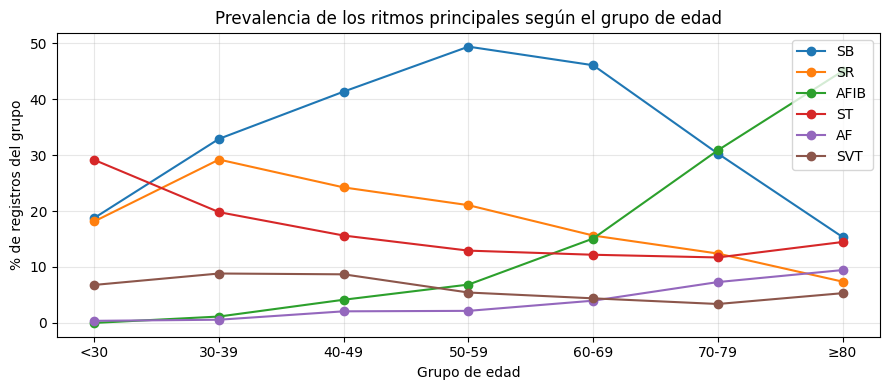

In [16]:
# TABLA: estadística descriptiva de la edad en cada ritmo
tabla_edad = pd.DataFrame({s: df["PatientAge"].describe() for s, df in ritmos.items()}).T
display(tabla_edad[["count", "mean", "std", "min", "50%", "max"]].round(1))

# Grupos de edad
bins = [0, 30, 40, 50, 60, 70, 80, 120]
etiquetas = ["<30", "30-39", "40-49", "50-59", "60-69", "70-79", "≥80"]
edad_grupo = pd.cut(diagnostics["PatientAge"], bins=bins, labels=etiquetas, right=False)
conteo_edad = pd.crosstab(edad_grupo, diagnostics[diagnosis_column])[orden]
pct_edad = conteo_edad.div(conteo_edad.sum(axis=1), axis=0) * 100   # % de cada ritmo dentro del grupo de edad

# GRÁFICO: evolución con la edad de los ritmos principales
principales = ["SB", "SR", "AFIB", "ST", "AF", "SVT"]
plt.figure(figsize=(9, 4))
for s in principales:
    plt.plot(etiquetas, pct_edad[s], marker="o", label=s)
plt.title("Prevalencia de los ritmos principales según el grupo de edad")
plt.xlabel("Grupo de edad"); plt.ylabel("% de registros del grupo")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

# Ecuaciones de *Higher order spectral analysis of ECG signals* (Kotriwar et al., 2018)
Una función por ecuación: (1) desviación del detrending, (2) compresión, (3) bispectro, (4) bicoherencia.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Ec. (1) — Desviación δ(n) entre señal original y detrendizada
$$\delta_{(n)}=\frac{1}{k}\sum_{i=1}^{k}\left(x_{(0)}(i)-x_{(n)}(i)\right)^2$$
El detrending se hace restando un ajuste polinomial de grado n (el artículo usa n = 20).

In [29]:
def desviacion_detrending(x0, n=20):
    """Ec. (1): detrendiza x0 con un polinomio de grado n y devuelve (delta_n, x_n)."""
    x0 = np.asarray(x0, dtype=float)
    k = len(x0)
    t = np.linspace(-1, 1, k)                       # eje normalizado: evita mal condicionamiento con n alto
    tendencia = np.polynomial.Polynomial.fit(t, x0, n)(t)
    x_n = x0 - tendencia                            # señal detrendizada
    delta = np.sum((x0 - x_n) ** 2) / k
    return delta, x_n

## Ec. (2) — Compresión (normalización min-max al rango [0, 1])
$$s(t_k)=\frac{c(t_k)-x_{min}}{x_{max}-x_{min}}$$

In [30]:
def compresion(x):
    """Ec. (2): lleva la señal al rango [0, 1] usando su mínimo y máximo."""
    x = np.asarray(x, dtype=float)
    x_min, x_max = x.min(), x.max()
    if x_max == x_min:
        raise ValueError("La señal es constante; no se puede comprimir.")
    return (x - x_min) / (x_max - x_min)

## Ec. (3) — Bispectro
$$b(f_1,f_2)=\sum_{j=1}^{N}X_j(f_1)\,X_j(f_2)\,X_j^*(f_1+f_2)$$
La señal se divide en N segmentos de longitud 8192 (como en el artículo) y se calcula la FFT de cada uno. Se evalúa hasta `fmax_hz` (el artículo usa 0–20 Hz).

In [31]:
def _segmentos_fft(x, nseg_len):
    x = np.asarray(x, dtype=float)
    N = len(x) // nseg_len
    if N < 1:
        raise ValueError("La señal es más corta que un segmento.")
    segs = x[:N * nseg_len].reshape(N, nseg_len)
    segs = segs - segs.mean(axis=1, keepdims=True)
    return np.fft.fft(segs, axis=1), N

def _indices(fs, nseg_len, fmax_hz):
    freqs = np.fft.fftfreq(nseg_len, d=1/fs)[:nseg_len // 2]
    kmax = np.searchsorted(freqs, fmax_hz, side="right")
    idx = np.arange(kmax)
    i1, i2 = np.meshgrid(idx, idx, indexing="ij")   # i1 -> f1, i2 -> f2
    return freqs[:kmax], i1, i2

def bispectro(x, fs=FS, nseg_len=500, fmax_hz=20):
    """Ec. (3): b(f1, f2) = sum_j Xj(f1) Xj(f2) Xj*(f1+f2). Devuelve (b, freqs, N)."""
    X, N = _segmentos_fft(x, nseg_len)
    freqs, i1, i2 = _indices(fs, nseg_len, fmax_hz)
    b = np.sum(X[:, i1] * X[:, i2] * np.conj(X[:, i1 + i2]), axis=0)
    return b, freqs, N

## Ec. (4) — Bicoherencia
$$B(f_1,f_2)=\frac{\left|\sum_{j=1}^{N}X_j(f_1)X_j(f_2)X_j^*(f_1+f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)X_j(f_2)X_j^*(f_1+f_2)\right|}$$
Valores en [0, 1]. Umbral de significancia del 80 %: $\sqrt{9.2/(2N)}$. Solo se conserva la región triangular $f_2>0,\ f_1\ge f_2$.

In [32]:
def bicoherencia(x, fs=FS, nseg_len=500, fmax_hz=20, triangular=True):
    """Ec. (4): bicoherencia normalizada en [0, 1]. Devuelve (B, freqs, umbral) con umbral = sqrt(9.2/(2N))."""
    X, N = _segmentos_fft(x, nseg_len)
    freqs, i1, i2 = _indices(fs, nseg_len, fmax_hz)
    triple = X[:, i1] * X[:, i2] * np.conj(X[:, i1 + i2])
    num = np.abs(np.sum(triple, axis=0))
    den = np.sum(np.abs(triple), axis=0)
    B = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    if triangular:                                   # región no redundante: f2 > 0, f1 >= f2
        B[~((i2 > 0) & (i1 >= i2))] = np.nan
    umbral = np.sqrt(9.2 / (2 * N))
    return B, freqs, umbral

## Ejemplo con una señal sintética
60 s a 1000 Hz con acoplamiento cuadrático de fase: componentes en 1.2 Hz, 3 Hz y 4.2 Hz (fase = suma de fases), más tendencia y ruido.

In [33]:
SUBCONJUNTO = ["SR"]

sub_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(SUBCONJUNTO)
].copy().reset_index(drop=True)

FILENAME_SUB = sub_diagnostics["FileName"].astype(str).tolist()
print(f"Registros en el subconjunto {SUBCONJUNTO}: {len(FILENAME_SUB)}")

def cargar_ecg(nombre, derivacion=DERIVACION):
    """Lee el .csv de un registro (5000 muestras x 12 derivaciones, sin encabezado) y devuelve una derivación."""
    datos = pd.read_csv(SIGNALS_DIR / f"{nombre}.csv", header=None)
    return datos.iloc[:, LEADS.index(derivacion)].to_numpy(dtype=float)

Registros en el subconjunto ['SR']: 1826


### Significado y utilidad del bispectro
El espectro de potencia (estadística de 2.º orden) dice **cuánta energía** hay en cada frecuencia, pero descarta la información de **fase**. Por eso no distingue entre una señal formada por componentes independientes y otra donde las componentes están relacionadas entre sí.

El **bispectro** es la transformada de Fourier del cumulante de 3.er orden (estadística de orden superior). Para cada pareja $(f_1, f_2)$ mide si la componente en $f_1+f_2$ tiene una fase igual a la suma de las fases de $f_1$ y $f_2$. Eso se llama **acoplamiento cuadrático de fase (QPC)** y aparece cuando un sistema **no lineal** mezcla frecuencias. La **bicoherencia** es el bispectro normalizado entre 0 y 1: un valor cercano a 1 indica acoplamiento fuerte y uno cercano a 0 indica componentes independientes.

**Propiedades útiles:**
- El bispectro de un proceso gaussiano es cero, así que suprime el ruido gaussiano aditivo.
- Conserva la información de fase y detecta no linealidades y desviaciones de la gaussianidad.

**Utilidad en ECG:** el corazón es un sistema no lineal. La actividad del nodo sinusal, la conducción y la repolarización generan armónicos acoplados de la frecuencia cardíaca. En ritmo sinusal se esperan picos de bicoherencia ordenados en múltiplos de la frecuencia cardíaca. En arritmias (por ejemplo, fibrilación auricular) ese acoplamiento se pierde o se dispersa. Por eso el número de frecuencias con bicoherencia significativa (sFSB) y la ubicación de los picos sirven como características para clasificar ritmos (Kotriwar et al., 2018; Nikias & Raghuveer, 1987).

Registro: MUSE_20180209_172046_21000 | N = 10 segmentos | umbral = 0.678


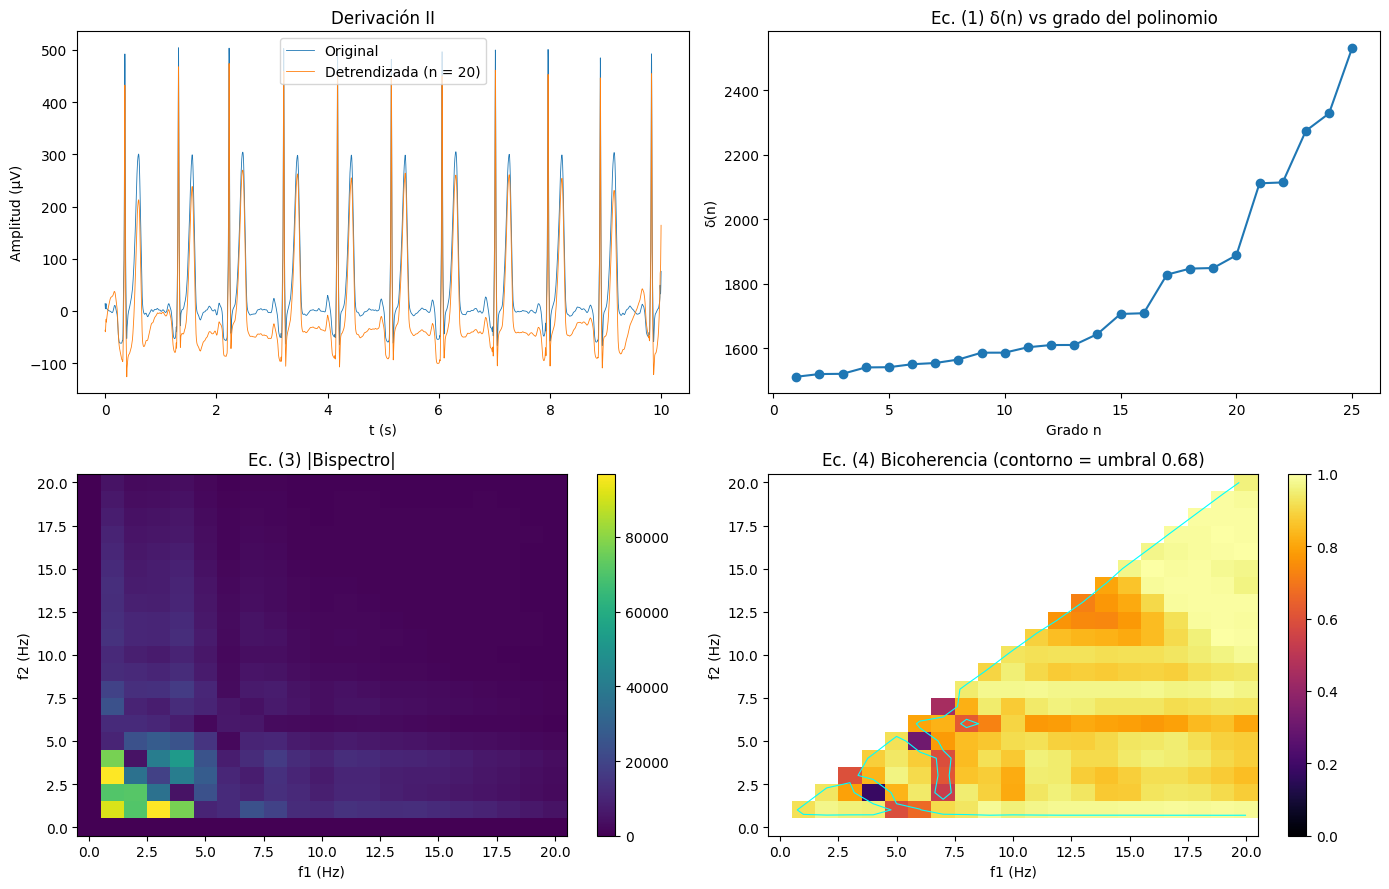

In [34]:
ejemplo = FILENAME_SUB[0]
x0 = cargar_ecg(ejemplo)
t = np.arange(len(x0)) / FS

# Ec. (1): δ(n) para varios grados del polinomio
grados = range(1, 26)
deltas = [desviacion_detrending(x0, n)[0] for n in grados]
_, x_det = desviacion_detrending(x0, 20)
s = compresion(x_det)                                   # Ec. (2)
b, freqs, N = bispectro(s)                              # Ec. (3)
B, freqs, umbral = bicoherencia(s)                      # Ec. (4)
print(f"Registro: {ejemplo} | N = {N} segmentos | umbral = {umbral:.3f}")

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0, 0].plot(t, x0, lw=0.6, label="Original")
ax[0, 0].plot(t, x_det, lw=0.6, label="Detrendizada (n = 20)")
ax[0, 0].set(xlabel="t (s)", ylabel="Amplitud (µV)", title=f"Derivación {DERIVACION}"); ax[0, 0].legend()
ax[0, 1].plot(list(grados), deltas, "o-")
ax[0, 1].set(xlabel="Grado n", ylabel="δ(n)", title="Ec. (1) δ(n) vs grado del polinomio")
im1 = ax[1, 0].pcolormesh(freqs, freqs, np.abs(b).T, shading="auto", cmap="viridis")
ax[1, 0].set(xlabel="f1 (Hz)", ylabel="f2 (Hz)", title="Ec. (3) |Bispectro|"); fig.colorbar(im1, ax=ax[1, 0])
im2 = ax[1, 1].pcolormesh(freqs, freqs, B.T, shading="auto", cmap="inferno", vmin=0, vmax=1)
ax[1, 1].contour(freqs, freqs, np.nan_to_num(B.T), levels=[umbral], colors="cyan", linewidths=0.8)
ax[1, 1].set(xlabel="f1 (Hz)", ylabel="f2 (Hz)", title=f"Ec. (4) Bicoherencia (contorno = umbral {umbral:.2f})")
fig.colorbar(im2, ax=ax[1, 1])
plt.tight_layout(); plt.show()

## Punto 4 — Frecuencia de máxima potencia (fMP)
La densidad espectral de potencia se estima con el método de **Welch** sobre la señal detrendizada y comprimida, con ventanas de 2 s (resolución de 0.5 Hz) y 50 % de traslape. Se busca el máximo entre 0.5 y 20 Hz para excluir la componente DC y el residuo de línea base.

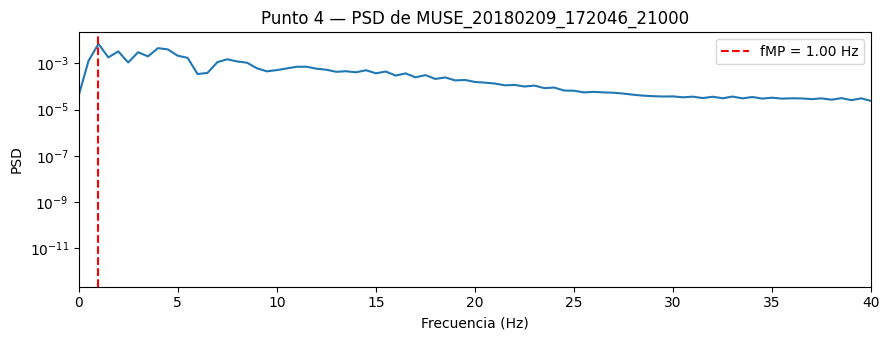

In [37]:
def frecuencia_max_potencia(s, fs=FS, fmin=0.5, fmax=20, nperseg=1000):
    """Punto 4: devuelve la frecuencia (Hz) con máxima potencia en [fmin, fmax] y la PSD."""
    f, Pxx = welch(s - np.mean(s), fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
    banda = (f >= fmin) & (f <= fmax)
    fMP = f[banda][np.argmax(Pxx[banda])]
    return fMP, f, Pxx

fMP, f, Pxx = frecuencia_max_potencia(s)
plt.figure(figsize=(9, 3.5))
plt.semilogy(f, Pxx); plt.axvline(fMP, color="r", ls="--", label=f"fMP = {fMP:.2f} Hz")
plt.xlim(0, 40); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD")
plt.title(f"Punto 4 — PSD de {ejemplo}"); plt.legend(); plt.tight_layout(); plt.show()

## Punto 5 — Suma de frecuencias significativas en bicoherencia (sFSB)
Se cuentan los pares $(f_1, f_2)$ de la región no redundante cuya bicoherencia supera $\sqrt{9.2/(2N)}$.

In [38]:
def suma_frec_significativas(s, fs=FS, nseg_len=500, fmax_hz=20):
    """Punto 5: número de pares (f1, f2) con bicoherencia > sqrt(9.2 / (2N))."""
    B, freqs, umbral = bicoherencia(s, fs=fs, nseg_len=nseg_len, fmax_hz=fmax_hz)
    return int(np.nansum(B > umbral)), umbral

sFSB, umbral = suma_frec_significativas(s)
print(f"{ejemplo}: sFSB = {sFSB} pares significativos (umbral = {umbral:.3f})")

MUSE_20180209_172046_21000: sFSB = 200 pares significativos (umbral = 0.678)
